# Buổi D7: Thực hành tổng hợp, từ câu hỏi đến bản báo cáo đáng tin

**Hiện trường.** Chị Hạnh có **442 hồ sơ bệnh nhân tiểu đường** (bộ dữ liệu mẫu `diabetes`) và một câu hỏi: *"mô hình dự đoán mức tiến triển bệnh sau một năm có đủ tốt để **xếp thứ tự ưu tiên theo dõi** không, và sai số cỡ bao nhiêu để hội đồng biết mà dùng?"*

Buổi này là **tổng ôn phần D** (D1 đến D6) trên một bài hồi quy trọn vẹn:

1. đặt câu hỏi, thước đo, mốc ngu; **niêm phong** tập thi;
2. so nhiều ứng viên **công bằng** (kiểm định chéo lặp, mọi bước trong pipeline);
3. chọn bằng **quy tắc một sai số chuẩn**, rồi vặn núm có kiểm soát;
4. **đường cong học**: thêm dữ liệu có đáng tiền không;
5. mở tập thi **một lần**, đo **khoảng dao động**, soi **theo nhóm con**;
6. chạy **phép thử đối chứng** (xáo nhãn) và viết bản báo cáo.

**Mindset:** bản báo cáo tốt không phải bản có con số đẹp nhất mà là bản để người đọc **quyết định đúng**.

**Lưu ý:** dữ liệu mẫu để học, **không dùng chẩn đoán hay ra quyết định y tế thật**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Câu hỏi, thước đo, mốc ngu, niêm phong tập thi |
| Chặng 2 | Năm ứng viên, so công bằng |
| Chặng 3 | Chọn bằng một sai số chuẩn, rồi vặn núm |
| Chặng 4 | Thêm dữ liệu có đáng tiền không? |
| Chặng 5 | Mở tập thi một lần: dao động và nhóm con |
| Chặng 6 | Phép thử đối chứng và bản báo cáo |

## Chặng 1: Câu hỏi, thước đo, mốc ngu, niêm phong tập thi

**Chốt trước khi chạy:**
- **Thước đo chính: MAE** (sai số tuyệt đối trung bình), tính bằng **điểm tiến triển** (đơn vị của `y`), dễ nói với hội đồng: *"trung bình lệch bao nhiêu điểm"*.
- **Thước đo phụ: R²** (hơn việc đoán trung bình bao nhiêu) và **tương quan thứ hạng** (nếu chỉ cần xếp thứ tự ưu tiên thì thứ hạng đúng mới là điều cốt lõi).
- **Mốc ngu:** luôn đoán trung bình của `y` trên tập học.
- **Niêm phong** tập thi 25%: không đụng đến chặng 5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2026)
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("train:", X_train.shape, "| sealed test:", X_test.shape)
print("dummy (always the mean) MAE:", round(mean_absolute_error(y_train, dummy.predict(X_train)), 1))

train: (331, 10) | sealed test: (111, 10)
dummy (always the mean) MAE: 64.8


**Giải thích từng dòng**

- `load_diabetes(return_X_y=True, as_frame=True)`: 442 bệnh nhân, 10 cột đo (tuổi, giới, BMI, huyết áp, 6 chỉ số máu), `y` là mức tiến triển sau một năm. Các cột đã được chuẩn hóa sẵn.
- `train_test_split(..., test_size=0.25, random_state=2026)`: chia 75/25; `X_test, y_test` **niêm phong** từ giờ đến chặng 5.
- `DummyRegressor(strategy='mean')`: mốc ngu của bài toán số: luôn đoán trung bình của `y` học.

**Cách đọc.** Tập học **331** ca, tập thi niêm phong **111** ca. Mốc ngu lệch trung bình khoảng **64,8** điểm, trên thang mà `y` dao động quanh 154. Mọi ứng viên phải **thắng rõ** mức này mới đáng dùng.

**Mang về chặng 1:** chốt câu hỏi, thước đo, mốc ngu và niêm phong tập thi **trước** khi so mô hình.

## Chặng 2: Năm ứng viên, so công bằng

Năm ứng viên: **hồi quy tuyến tính**, **Ridge**, **Lasso** (B6), **k-NN hồi quy**, **SVR** (SVM cho số), **cây quyết định hồi quy** (C5, giới hạn độ sâu). Mỗi ứng viên nằm trong **pipeline** (D3), đo trên **cùng cách chia** bằng kiểm định chéo lặp (D1): 5 phần × 4 lần = 20 điểm.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RepeatedKFold, cross_val_score
candidates = {
    "linear": make_pipeline(StandardScaler(), LinearRegression()),
    "ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "lasso": make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
    "knn": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15)),
    "svr": make_pipeline(StandardScaler(), SVR(C=100)),
    "tree": DecisionTreeRegressor(max_depth=3, random_state=0),
}
cv = RepeatedKFold(n_splits=5, n_repeats=4, random_state=0)
rows = []
for name, m in candidates.items():
    s = -cross_val_score(m, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    rows.append({"model": name, "MAE": s.mean(), "std": s.std(), "se": s.std() / np.sqrt(len(s))})
res = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print(res.round(2).to_string(index=False))

 model   MAE  std   se
 ridge 45.13 3.66 0.82
linear 45.26 3.95 0.88
   svr 45.28 4.68 1.05
 lasso 45.30 3.70 0.83
   knn 46.92 3.70 0.83
  tree 51.60 4.80 1.07


**Giải thích từng dòng**

- `Ridge(alpha=10) / Lasso(alpha=1.0)`: hai biến thể có 'phanh' chống học vẹt (B6). `alpha` là độ mạnh của phanh; ta tạm đặt, sẽ vặn ở chặng 3.
- `KNeighborsRegressor(n_neighbors=15)`: đoán bằng trung bình `y` của 15 bệnh nhân giống nhất.
- `SVR(C=100)`: SVM cho số: khớp một dải quanh đường cong, `C` là mức nghiêm khắc.
- `RepeatedKFold(n_splits=5, n_repeats=4, ...)`: kiểm định chéo lặp cho hồi quy (không cần giữ tỉ lệ nhóm).
- `s.std() / np.sqrt(len(s))`: sai số chuẩn: độ dao động của điểm **trung bình** (không phải của từng phần).

**Cách đọc.**
- **Con số:** MAE tốt nhất **45,1** (ridge), kém nhất **51,6** (tree). Mốc ngu khoảng **64,8**.
- **Bức tranh:** các mô hình tuyến tính thường nằm cạnh nhau, dữ liệu 442 ca ít cột nên mô hình phức tạp **không** có lợi thế rõ. Hãy xem cột `se` để biết ứng viên nào thật sự khác nhau.
- **Câu hỏi tiếp:** chọn ai khi nhiều ứng viên sát nhau?

**Mang về chặng 2:** so công bằng: cùng cách chia, pipeline, nhiều lần lặp, ghi cả sai số chuẩn.

## Chặng 3: Chọn bằng một sai số chuẩn, rồi vặn núm

**Câu hỏi:** những ứng viên nào "ngang" ứng viên tốt nhất?

**Quy tắc một sai số chuẩn** (C9): chọn mô hình **đơn giản nhất** có MAE không vượt `MAE tốt nhất + sai số chuẩn của nó`.

In [4]:
limit = res.loc[0, "MAE"] + res.loc[0, "se"]
within = res[res["MAE"] <= limit]
print("limit:", round(limit, 2))
print(within[["model", "MAE"]].round(2).to_string(index=False))

limit: 45.95
 model   MAE
 ridge 45.13
linear 45.26
   svr 45.28
 lasso 45.30


**Giải thích từng dòng**

- `res.loc[0, 'MAE'] + res.loc[0, 'se']`: ngưỡng: điểm tốt nhất cộng một sai số chuẩn.
- `res[res['MAE'] <= limit]`: lọc các dòng có MAE nằm trong ngưỡng: những ứng viên 'ngang' nhau.

In [5]:
from sklearn.model_selection import GridSearchCV
pipe = make_pipeline(StandardScaler(), Ridge())
search = GridSearchCV(pipe, {"ridge__alpha": np.logspace(-2, 3, 11)}, cv=cv, scoring="neg_mean_absolute_error").fit(X_train, y_train)
print("best alpha:", round(search.best_params_["ridge__alpha"], 3), "| CV MAE:", round(-search.best_score_, 2))

best alpha: 10.0 | CV MAE: 45.13


**Giải thích từng dòng**

- `np.logspace(-2, 3, 11)`: 11 giá trị `alpha` từ 0,01 đến 1000 theo thang log (D4).
- `scoring='neg_mean_absolute_error'`: chấm bằng MAE (đổi dấu vì sklearn muốn điểm cao là tốt).

**Cách đọc.**
- **Con số:** các ứng viên trong dải một sai số chuẩn: **ridge, linear, svr, lasso**. Sau khi vặn `alpha` cho Ridge, MAE kiểm định chéo **45,13** (trước đó 45,13).
- **Bức tranh:** nếu nhiều ứng viên cùng nằm trong dải, chọn cái **đơn giản và dễ giải thích nhất** (thường là tuyến tính có phanh). Vặn núm chỉ nhích thêm một chút; ta đã thấy ở D4 rằng điểm tốt nhất sau khi vặn là lạc quan, nên ta không tin vào phần nhích này.
- **Ta chọn:** Ridge với `alpha` ở trên. Quyết định này **chỉ dựa trên tập học**.

**Mang về chặng 3:** chọn mô hình đơn giản nhất còn nằm trong một sai số chuẩn của người tốt nhất; vặn núm sau khi chọn.

## Chặng 4: Thêm dữ liệu có đáng tiền không?

Dùng đường cong học (D2) cho mô hình đã chọn. Nếu đường xác nhận đã phẳng, thu thêm hồ sơ cùng loại gần như không giúp.

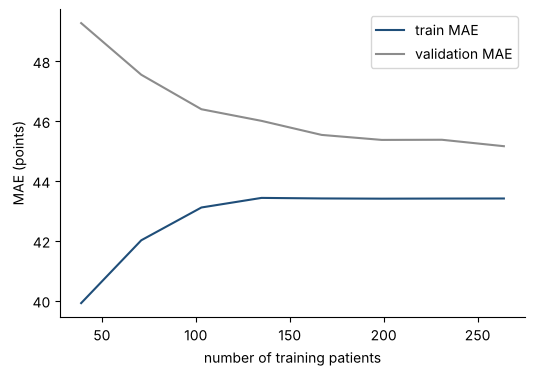

validation MAE at smallest / largest size: 49.27 / 45.16


In [6]:
from sklearn.model_selection import learning_curve
chosen = search.best_estimator_
n_tr, tr_s, va_s = learning_curve(chosen, X_train, y_train, train_sizes=np.linspace(0.15, 1.0, 8), cv=cv, scoring="neg_mean_absolute_error", shuffle=True, random_state=0)
fig, ax = plt.subplots()
ax.plot(n_tr, -tr_s.mean(axis=1), color=BLUE, label="train MAE")
ax.plot(n_tr, -va_s.mean(axis=1), color=GRAY, label="validation MAE")
ax.set_xlabel("number of training patients"); ax.set_ylabel("MAE (points)"); ax.legend()
plt.show()
print("validation MAE at smallest / largest size:", round(-va_s.mean(axis=1)[0], 2), "/", round(-va_s.mean(axis=1)[-1], 2))

**Giải thích từng dòng**

- `scoring='neg_mean_absolute_error'`: ở đường cong học, vì dùng sai số nên đường **xuống** là tốt (đổi dấu bằng dấu trừ).
- `-tr_s.mean(axis=1)`: đổi dấu lại thành MAE dương và lấy trung bình theo phần.

**Cách đọc.**
- **Con số:** MAE xác nhận từ **49,3** (ít dữ liệu) xuống **45,2** (đủ dữ liệu); MAE phần học cuối **43,4**.
- **Bức tranh:** hai đường đã **gần nhau** và đường xác nhận **gần phẳng** ở phía phải: mô hình tuyến tính 10 cột không còn nhiều chỗ để học thêm. Tăng dữ liệu cùng loại sẽ không đổi nhiều; muốn tốt hơn cần **cột mới có ý nghĩa** (xét nghiệm mới), không phải thêm hồ sơ.

**Mang về chặng 4:** đường cong học giúp ta nói với hội đồng: *"đừng bỏ tiền thu thêm hồ sơ cùng loại, hãy bỏ tiền đo thêm chỉ số mới"*.

## Chặng 5: Mở tập thi một lần, đo dao động và soi nhóm con

Giờ mới mở tập thi niêm phong. Học lại mô hình đã chọn trên **toàn bộ tập học**, chấm **một lần**, rồi báo cáo ba thứ: **con số**, **khoảng dao động** (bootstrap), và **kết quả theo nhóm con**.

In [7]:
from scipy.stats import spearmanr
final = chosen.fit(X_train, y_train)
pred = final.predict(X_test)
mae_test = mean_absolute_error(y_test, pred)
rho = spearmanr(y_test, pred)[0]
print("test MAE:", round(mae_test, 1), "| R2:", round(r2_score(y_test, pred), 3), "| rank correlation:", round(rho, 3))
print("dummy MAE on the same test set:", round(mean_absolute_error(y_test, dummy.predict(X_test)), 1))

test MAE: 43.0 | R2: 0.516 | rank correlation: 0.72
dummy MAE on the same test set: 69.2


**Giải thích từng dòng**

- `chosen.fit(X_train, y_train)`: học lại pipeline đã chọn trên toàn bộ phần học.
- `spearmanr(y_test, pred)[0]`: tương quan **thứ hạng** giữa thực tế và dự đoán (từ -1 đến 1). Quan trọng nếu mục đích là **xếp thứ tự ưu tiên**. `[0]` lấy hệ số, bỏ giá trị p.

In [8]:
rng = np.random.RandomState(0)
errs = np.abs(y_test.values - pred)
boot = [errs[rng.randint(0, len(errs), len(errs))].mean() for _ in range(2000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print("MAE 95% interval:", round(lo, 1), "-", round(hi, 1))

MAE 95% interval: 36.8 - 49.3


**Giải thích từng dòng**

- `errs[rng.randint(0, len(errs), len(errs))]`: **bootstrap**: bốc lại ngẫu nhiên có hoàn lại chính các sai số, cùng cỡ, để mô phỏng 'nếu có một tập thi khác'.
- `np.percentile(boot, [2.5, 97.5])`: lấy hai đầu của 95% giữa: khoảng dao động của MAE (đã học ở C8).

In [9]:
groups_df = X_test.copy()
groups_df["abs_error"] = errs
groups_df["bmi_group"] = pd.qcut(groups_df["bmi"], 3, labels=["low", "mid", "high"])
groups_df["age_group"] = pd.qcut(groups_df["age"], 3, labels=["young", "mid", "old"])
print(groups_df.groupby("bmi_group", observed=True)["abs_error"].agg(["mean", "count"]).round(1))
print(groups_df.groupby("age_group", observed=True)["abs_error"].agg(["mean", "count"]).round(1))

           mean  count
bmi_group             
low        35.5     39
mid        47.3     36
high       46.8     36
           mean  count
age_group             
young      46.9     37
mid        46.7     37
old        35.5     37


**Giải thích từng dòng**

- `X_test.copy()`: sao chép bảng thi để thêm cột mà không làm hỏng bản gốc.
- `pd.qcut(groups_df['bmi'], 3, labels=[...])`: chia thành 3 nhóm **số ca bằng nhau** theo BMI (đã chuẩn hóa sẵn trong bộ dữ liệu nên chỉ để xếp nhóm).
- `.groupby(...)['abs_error'].agg(['mean', 'count'])`: MAE và số ca của từng nhóm.

**Cách đọc.**
- **Con số:** MAE trên tập thi **43,0** điểm (mốc ngu **69,2**), khoảng 95% **36,8 đến 49,3**; tương quan thứ hạng **0,72**.
- **Bức tranh:** mô hình **hơn mốc ngu**, nhưng sai số vẫn đáng kể so với thang của `y`. Về **xếp thứ tự ưu tiên**, tương quan thứ hạng cỡ 0,72 là **khá** nhưng không hoàn hảo: nhiều ca sẽ bị xếp lệch.
- **Nhóm con:** nhìn hai bảng ở trên để xem nhóm nào sai nhiều hơn. Mỗi nhóm chỉ có khoảng 37 ca, nên **chênh lệch nhỏ giữa các nhóm không đáng tin**; chỉ chênh lệch lớn mới cần xem xét kỹ.

**Mang về chặng 5:** báo cáo luôn kèm khoảng dao động và kết quả theo nhóm con, không chỉ một con số.

## Chặng 6: Phép thử đối chứng và bản báo cáo

**Phép thử đối chứng** (C9): chạy lại **toàn bộ quy trình** với nhãn bị xáo. Nếu quy trình sạch, R² phải quanh 0 hoặc âm; nếu cao thì có rò rỉ ở đâu đó.

In [10]:
y_shuffled = pd.Series(np.random.RandomState(1).permutation(y_train.values), index=y_train.index)
control = -cross_val_score(chosen, X_train, y_shuffled, cv=cv, scoring="neg_mean_absolute_error").mean()
control_r2 = cross_val_score(chosen, X_train, y_shuffled, cv=cv, scoring="r2").mean()
print("shuffled-label control: CV MAE", round(control, 1), "| CV R2", round(control_r2, 3))

shuffled-label control: CV MAE 65.7 | CV R2 -0.056


**Giải thích từng dòng**

- `np.random.RandomState(1).permutation(y_train.values)`: xáo thứ tự nhãn: phá mối liên hệ thật giữa cột và nhãn.
- `scoring='r2'`: chấm bằng R²: 0 là ngang đoán trung bình, âm là tệ hơn.

**Cách đọc.** Với nhãn đã xáo, R² kiểm định chéo là **-0,056** (quanh 0 hoặc hơi âm là đúng) và MAE **65,7** (không hơn mốc ngu). Quy trình **không có dấu hiệu rò rỉ** theo phép thử này.

## Bản báo cáo gửi hội đồng

**Câu hỏi:** mô hình có đủ tốt để xếp thứ tự ưu tiên theo dõi không?

**Dữ liệu:** 442 hồ sơ mẫu, 10 cột. Tập thi 111 ca, niêm phong và chỉ mở một lần.

**Mô hình:** Ridge trên cột đã chuẩn hóa (`alpha` = 10,00), chọn bằng kiểm định chéo lặp, quy tắc một sai số chuẩn.

**Kết quả trên tập thi:** MAE **43,0** điểm (khoảng 95%: 36,8 đến 49,3); mốc ngu 69,2. Tương quan thứ hạng 0,72.

**Hạn chế:**
- tập thi chỉ 111 ca nên khoảng dao động rộng, và nhóm con quá nhỏ để kết luận;
- dữ liệu mẫu từ một nghiên cứu cũ, chưa chắc giống bệnh nhân bệnh viện hiện tại;
- mô hình dự đoán **mức tiến triển**, không giải thích **nguyên nhân**.

**Khuyến nghị:** dùng như **công cụ gợi ý thứ tự**, **không** thay thế quyết định của bác sĩ; **đo thêm chỉ số mới** thay vì thu thêm hồ sơ cùng loại; thử lại trên dữ liệu của chính bệnh viện trước khi triển khai.

**Bài học nghề:** điểm không phải thứ cần khoe; điều cần khoe là **ta biết điểm đó đáng tin đến đâu và dùng nó vào việc gì**.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Chốt câu hỏi, thước đo bằng đơn vị của quyết định, mốc ngu; niêm phong tập thi. |
| 2 | So ứng viên công bằng: pipeline, kiểm định chéo lặp, ghi sai số chuẩn. |
| 3 | Quy tắc một sai số chuẩn; vặn núm sau, không tin điểm tốt nhất sau khi vặn. |
| 4 | Đường cong học: thêm hồ sơ cùng loại có đáng tiền không. |
| 5 | Mở tập thi một lần; kèm khoảng dao động và nhóm con. |
| 6 | Phép thử đối chứng rồi viết báo cáo có hạn chế và khuyến nghị. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Luôn đoán trung bình | mốc ngu (hồi quy) | `DummyRegressor` |
| Thi nhiều lần cùng cách chia | kiểm định chéo lặp | `RepeatedKFold` |
| Độ dao động của điểm trung bình | sai số chuẩn | `std / np.sqrt(n)` |
| Chọn cái đơn giản khi ngang nhau | quy tắc một sai số chuẩn | `MAE <= best + se` |
| Xếp thứ tự có đúng không | tương quan thứ hạng | `spearmanr` |
| Bốc lại để thấy dao động | bootstrap | `rng.randint`, `np.percentile` |
| Chia thành ba nhóm đều | phân vị | `pd.qcut` |
| Chạy lại với nhãn xáo | phép thử đối chứng | `rng.permutation` |

**Thử thách tự làm**

1. Đổi `random_state` của lần chia 75/25 vài lần và chạy lại toàn bộ. MAE trên tập thi dao động bao nhiêu? Điều đó nói gì về việc tin một lần chia duy nhất?
2. Thêm `ElasticNet` vào danh sách ứng viên (chặng 2). Nó nằm trong dải một sai số chuẩn không?
3. Lặp lại bài với `scoring='neg_root_mean_squared_error'`. Ứng viên tốt nhất có đổi không? Vì sao?
4. Viết lại phần khuyến nghị cho trường hợp hội đồng chỉ chấp nhận mô hình khi MAE trên tập thi dưới 40 điểm: kết luận của bạn là gì, và dựa vào con số nào?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Chốt thước đo và mốc ngu trước khi chạy mô hình.
- [ ] So ứng viên công bằng bằng pipeline và kiểm định chéo lặp.
- [ ] Áp dụng quy tắc một sai số chuẩn.
- [ ] Dùng đường cong học để trả lời câu hỏi thêm dữ liệu.
- [ ] Báo cáo kết quả kèm khoảng dao động và nhóm con.
- [ ] Viết báo cáo có hạn chế và khuyến nghị thật thà.

## Phần thưởng (Tip pro): Khi nào KHÔNG nên dùng mô hình này


Nếu hội đồng cần **nói chắc về một bệnh nhân cụ thể** ("ca này tiến triển bao nhiêu điểm"), sai số vài chục điểm là quá lớn; mô hình chỉ hợp để **xếp thứ tự đại khái** cho cả nhóm. Và nếu một **luật viết tay đơn giản** (ví dụ "chọn người có BMI cao nhất", như đã thử ở A3) cho kết quả ngang mô hình, thì dùng luật: dễ giải thích, dễ kiểm tra, không cần bảo trì mô hình. Máy học đáng giá khi nó **hơn rõ** những cách đơn giản đó.